In [1]:

########################################
# Cell 1. Initialize Environment
########################################

import os
import sys
import subprocess
from pathlib import Path
import importlib.metadata as metadata

# Define project directory
BASE_DIR = Path("/data/Zira/Chemprop_Kd_Mann/3_53")

# Create experiment directories
FOLDERS = {
    "dataset": BASE_DIR / "dataset",
    "splits": BASE_DIR / "splits",
    "models": BASE_DIR / "models",
    "predictions": BASE_DIR / "predictions",
    "evaluation": BASE_DIR / "evaluation",
}

for folder in FOLDERS.values():
    folder.mkdir(parents=True, exist_ok=True)

# Check Python and Chemprop versions
print("Python version:", sys.version)
print("Python executable:", sys.executable)

try:
    print("Chemprop version:", metadata.version("chemprop"))
except metadata.PackageNotFoundError:
    print("Chemprop is not installed in this environment.")

# Check GPU availability
try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))

except ImportError:
    print("PyTorch is not installed.")

# Display project structure
print("\nProject directory:", BASE_DIR)

for name, path in FOLDERS.items():
    print(f"{name}: {path}")


Python version: 3.11.18 (main, Oct 26 2026, 11:35:17) [GCC 15.3.0]
Python executable: /workspace/miniforge3/envs/chemprop/bin/python
Chemprop version: 2.3.1
PyTorch version: 2.6.0+cu126
CUDA available: True
GPU name: Tesla V100-SXM2-32GB

Project directory: /data/Zira/Chemprop_Kd_Mann/3_53
dataset: /data/Zira/Chemprop_Kd_Mann/3_53/dataset
splits: /data/Zira/Chemprop_Kd_Mann/3_53/splits
models: /data/Zira/Chemprop_Kd_Mann/3_53/models
predictions: /data/Zira/Chemprop_Kd_Mann/3_53/predictions
evaluation: /data/Zira/Chemprop_Kd_Mann/3_53/evaluation


In [2]:

########################################
# Cell 2. Load and Validate Dataset
########################################

import pandas as pd

# Define dataset path
DATA_PATH = Path("/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

# Check required columns
required_columns = ["Smiles", "pKd"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Select required columns
df = df[["Smiles", "pKd"]].copy()

# Validate data
df["Smiles"] = df["Smiles"].astype(str).str.strip()
df["pKd"] = pd.to_numeric(df["pKd"], errors="coerce")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate SMILES:", df["Smiles"].duplicated().sum())

print("\npKd statistics:")
print(df["pKd"].describe())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (53, 2)

Missing values:
Smiles    0
pKd       0
dtype: int64

Duplicate SMILES: 0

pKd statistics:
count    53.000000
mean      4.394154
std       0.464943
min       3.568636
25%       4.060481
50%       4.376751
75%       4.677781
max       5.552842
Name: pKd, dtype: float64

First five rows:


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909


In [3]:

########################################
# Cell 3. Validate Molecular Structures
########################################

from rdkit import Chem

# Validate SMILES using RDKit
df["Molecule"] = df["Smiles"].apply(Chem.MolFromSmiles)

# Count invalid structures
invalid_count = df["Molecule"].isna().sum()

print("Total compounds:", len(df))
print("Valid molecules:", len(df) - invalid_count)
print("Invalid molecules:", invalid_count)

# Stop if invalid molecules are found
if invalid_count > 0:
    print("\nInvalid SMILES:")
    display(df.loc[df["Molecule"].isna(), ["Smiles", "pKd"]])
else:
    print("\nAll molecular structures are valid.")

# Remove temporary molecule column
df = df.drop(columns=["Molecule"])

# Save validated dataset
VALIDATED_DATA_PATH = FOLDERS["dataset"] / "USP5_53_pKd_validated.csv"

df.to_csv(VALIDATED_DATA_PATH, index=False)

print("\nValidated dataset saved to:")
print(VALIDATED_DATA_PATH)


Total compounds: 53
Valid molecules: 53
Invalid molecules: 0

All molecular structures are valid.

Validated dataset saved to:
/data/Zira/Chemprop_Kd_Mann/3_53/dataset/USP5_53_pKd_validated.csv


In [4]:

########################################
# Cell 4. Generate Repeated 5-Fold Splits
########################################

import json
import numpy as np
from sklearn.model_selection import KFold, train_test_split

# Define cross-validation settings
REPETITIONS = 5
N_FOLDS = 5

SPLIT_SEEDS = [42, 123, 202, 303, 404]
VALIDATION_RATIO = 0.10

# Generate repeated cross-validation splits
all_splits = []

for repetition, seed in enumerate(SPLIT_SEEDS, start=1):

    kf = KFold(
        n_splits=N_FOLDS,
        shuffle=True,
        random_state=seed
    )

    for fold, (train_val_idx, test_idx) in enumerate(
        kf.split(df), start=1
    ):

        # Split training data into training and validation
        train_idx, val_idx = train_test_split(
            train_val_idx,
            test_size=VALIDATION_RATIO,
            random_state=seed + fold
        )

        split_info = {
            "repetition": repetition,
            "fold": fold,
            "seed": seed,
            "train": train_idx.tolist(),
            "val": val_idx.tolist(),
            "test": test_idx.tolist()
        }

        all_splits.append(split_info)

        print(
            f"Repetition {repetition}, Fold {fold}: "
            f"Train={len(train_idx)}, "
            f"Validation={len(val_idx)}, "
            f"Test={len(test_idx)}"
        )

# Save split information
SPLIT_SUMMARY_PATH = FOLDERS["splits"] / "repeated_5fold_split_summary.json"

with open(SPLIT_SUMMARY_PATH, "w") as file:
    json.dump(all_splits, file, indent=4)

print("\nTotal model splits:", len(all_splits))
print("Split summary saved to:")
print(SPLIT_SUMMARY_PATH)


Repetition 1, Fold 1: Train=37, Validation=5, Test=11
Repetition 1, Fold 2: Train=37, Validation=5, Test=11
Repetition 1, Fold 3: Train=37, Validation=5, Test=11
Repetition 1, Fold 4: Train=38, Validation=5, Test=10
Repetition 1, Fold 5: Train=38, Validation=5, Test=10
Repetition 2, Fold 1: Train=37, Validation=5, Test=11
Repetition 2, Fold 2: Train=37, Validation=5, Test=11
Repetition 2, Fold 3: Train=37, Validation=5, Test=11
Repetition 2, Fold 4: Train=38, Validation=5, Test=10
Repetition 2, Fold 5: Train=38, Validation=5, Test=10
Repetition 3, Fold 1: Train=37, Validation=5, Test=11
Repetition 3, Fold 2: Train=37, Validation=5, Test=11
Repetition 3, Fold 3: Train=37, Validation=5, Test=11
Repetition 3, Fold 4: Train=38, Validation=5, Test=10
Repetition 3, Fold 5: Train=38, Validation=5, Test=10
Repetition 4, Fold 1: Train=37, Validation=5, Test=11
Repetition 4, Fold 2: Train=37, Validation=5, Test=11
Repetition 4, Fold 3: Train=37, Validation=5, Test=11
Repetition 4, Fold 4: Train=

In [5]:

########################################
# Cell 5. Validate Cross-Validation Splits
########################################

all_valid = True

for repetition in range(1, REPETITIONS + 1):

    repetition_splits = [
        split for split in all_splits
        if split["repetition"] == repetition
    ]

    test_indices = []

    for split in repetition_splits:

        train_idx = set(split["train"])
        val_idx = set(split["val"])
        test_idx = set(split["test"])

        # Check overlap between datasets
        assert train_idx.isdisjoint(val_idx)
        assert train_idx.isdisjoint(test_idx)
        assert val_idx.isdisjoint(test_idx)

        # Check all compounds are included
        combined_idx = train_idx | val_idx | test_idx
        assert combined_idx == set(range(len(df)))

        test_indices.extend(split["test"])

    # Check every compound appears once in test set
    test_counts = pd.Series(test_indices).value_counts()

    assert len(test_counts) == len(df)
    assert (test_counts == 1).all()

    print(
        f"Repetition {repetition}: "
        "No overlap. All compounds tested exactly once."
    )

print("\nAll split integrity checks passed.")


Repetition 1: No overlap. All compounds tested exactly once.
Repetition 2: No overlap. All compounds tested exactly once.
Repetition 3: No overlap. All compounds tested exactly once.
Repetition 4: No overlap. All compounds tested exactly once.
Repetition 5: No overlap. All compounds tested exactly once.

All split integrity checks passed.


In [6]:

########################################
# Cell 6. Export Chemprop Split Files
########################################

for split in all_splits:

    repetition = split["repetition"]
    fold = split["fold"]

    chemprop_split = [{
        "train": split["train"],
        "val": split["val"],
        "test": split["test"]
    }]

    split_filename = (
        f"rep_{repetition}_fold_{fold}.json"
    )

    split_path = FOLDERS["splits"] / split_filename

    with open(split_path, "w") as file:
        json.dump(chemprop_split, file, indent=4)

print("Total Chemprop split files:", len(all_splits))

print("\nExample split file:")
print(
    FOLDERS["splits"] /
    "rep_1_fold_1.json"
)

print("\nAll split files exported successfully.")


Total Chemprop split files: 25

Example split file:
/data/Zira/Chemprop_Kd_Mann/3_53/splits/rep_1_fold_1.json

All split files exported successfully.


In [7]:

########################################
# Cell 7. Define Model Configuration
########################################

MODEL_CONFIG = {
    "task_type": "regression",
    "smiles_column": "Smiles",
    "target_column": "pKd",
    "epochs": 100,
    "batch_size": 16,
    "message_hidden_dim": 300,
    "depth": 3,
    "dropout": 0.2,
    "patience": 15,
    "accelerator": "gpu",
    "devices": 1,
    "metrics": ["rmse", "mae", "r2"],
    "model_seed": 42
}

print("Chemprop model configuration:")

for key, value in MODEL_CONFIG.items():
    print(f"{key}: {value}")


Chemprop model configuration:
task_type: regression
smiles_column: Smiles
target_column: pKd
epochs: 100
batch_size: 16
message_hidden_dim: 300
depth: 3
dropout: 0.2
patience: 15
accelerator: gpu
devices: 1
metrics: ['rmse', 'mae', 'r2']
model_seed: 42


In [8]:

########################################
# Cell 8. Run Pilot Model
########################################

import subprocess
import sys

# Define pilot experiment
PILOT_REP = 1
PILOT_FOLD = 1

PILOT_SPLIT = (
    FOLDERS["splits"] /
    f"rep_{PILOT_REP}_fold_{PILOT_FOLD}.json"
)

PILOT_OUTPUT = (
    FOLDERS["models"] /
    f"rep_{PILOT_REP}_fold_{PILOT_FOLD}"
)

PILOT_OUTPUT.mkdir(parents=True, exist_ok=True)

# Chemprop command entry point
cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

# Build training command
cmd = [
    sys.executable,
    "-c",
    cli_code,
    "train",
    "--data-path", str(VALIDATED_DATA_PATH),
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--task-type", "regression",
    "--split", "RANDOM",
    "--splits-file", str(PILOT_SPLIT),
    "--output-dir", str(PILOT_OUTPUT),
    "--epochs", str(MODEL_CONFIG["epochs"]),
    "--batch-size", str(MODEL_CONFIG["batch_size"]),
    "--message-hidden-dim", str(MODEL_CONFIG["message_hidden_dim"]),
    "--depth", str(MODEL_CONFIG["depth"]),
    "--dropout", str(MODEL_CONFIG["dropout"]),
    "--patience", str(MODEL_CONFIG["patience"]),
    "--accelerator", MODEL_CONFIG["accelerator"],
    "--devices", str(MODEL_CONFIG["devices"]),
    "--pytorch-seed", str(MODEL_CONFIG["model_seed"]),
    "--metrics", "rmse", "mae", "r2"
]

print("Starting pilot model...")
print("Repetition:", PILOT_REP)
print("Fold:", PILOT_FOLD)
print("Split file:", PILOT_SPLIT)
print("Output directory:", PILOT_OUTPUT)

# Execute Chemprop training
result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)
print("\nStandard output:")
print(result.stdout[-10000:])

if result.stderr:
    print("\nStandard error:")
    print(result.stderr[-5000:])

if result.returncode != 0:
    raise RuntimeError("Pilot model training failed.")

print("\nPilot model completed successfully.")


Starting pilot model...
Repetition: 1
Fold: 1
Split file: /data/Zira/Chemprop_Kd_Mann/3_53/splits/rep_1_fold_1.json
Output directory: /data/Zira/Chemprop_Kd_Mann/3_53/models/rep_1_fold_1

Return code: 0

Standard output:
  train_loss_step:  
                                                              0.726 val_loss:   
                                                              0.392             
                                                              train_loss_epoch: 
                                                              0.434             
Epoch 82/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 76.01it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.726 val_loss:   
                                                              0.392             
                                                              train_loss_epoch: 
                             

In [9]:

########################################
# Cell 9. Inspect Pilot Output
########################################

# List generated files
for root, dirs, files in os.walk(PILOT_OUTPUT):

    for filename in files:
        file_path = Path(root) / filename

        print(
            f"{file_path.relative_to(PILOT_OUTPUT)} "
            f"({file_path.stat().st_size / 1024:.2f} KB)"
        )

# Locate prediction files
prediction_files = list(PILOT_OUTPUT.rglob("*test*"))

print("\nTest-related files:")

for file_path in prediction_files:
    print(file_path)


config.toml (1.24 KB)
splits.json (0.23 KB)
model_0/test_predictions.csv (0.70 KB)
model_0/best.pt (1258.89 KB)
model_0/checkpoints/last.ckpt (3755.54 KB)
model_0/checkpoints/best-epoch=69-val_loss=0.19.ckpt (3755.54 KB)
model_0/trainer_logs/version_0/hparams.yaml (0.08 KB)
model_0/trainer_logs/version_0/metrics.csv (10.08 KB)

Test-related files:
/data/Zira/Chemprop_Kd_Mann/3_53/models/rep_1_fold_1/model_0/test_predictions.csv


In [10]:

########################################
# Cell 10. Inspect Prediction Format
########################################

PILOT_PREDICTION_PATH = (
    PILOT_OUTPUT / "model_0" / "test_predictions.csv"
)

pilot_predictions = pd.read_csv(PILOT_PREDICTION_PATH)

print("Prediction file shape:", pilot_predictions.shape)

print("\nPrediction columns:")
print(pilot_predictions.columns.tolist())

print("\nPrediction preview:")
display(pilot_predictions.head())

print("\nOriginal test data preview:")

pilot_test_indices = all_splits[0]["test"]

display(
    df.iloc[pilot_test_indices][["Smiles", "pKd"]].head()
)


Prediction file shape: (11, 2)

Prediction columns:
['Smiles', 'pKd']

Prediction preview:


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.884232
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,4.660993
2,Cc1ccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3)...,4.141522
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,4.533690
4,O=C(O)CNC(=O)c1csc(S(=O)(=O)N2CCC(c3ccccc3)CC2)c1,4.433590



Original test data preview:


,Smiles,pKd
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
5,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.552842
12,Cc1ccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3)...,4.721246
13,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,3.677781
17,O=C(O)CNC(=O)c1csc(S(=O)(=O)N2CCC(c3ccccc3)CC2)c1,4.173925


In [11]:

########################################
# Cell 11. Run Remaining Cross-Validation Models
########################################

import time

training_results = []

for split in all_splits:

    repetition = split["repetition"]
    fold = split["fold"]

    output_dir = (
        FOLDERS["models"] /
        f"rep_{repetition}_fold_{fold}"
    )

    prediction_path = (
        output_dir / "model_0" / "test_predictions.csv"
    )

    # Skip completed models
    if prediction_path.exists():
        print(
            f"Skipping Repetition {repetition}, "
            f"Fold {fold}: already completed."
        )
        continue

    split_path = (
        FOLDERS["splits"] /
        f"rep_{repetition}_fold_{fold}.json"
    )

    output_dir.mkdir(parents=True, exist_ok=True)

    cmd = [
        sys.executable,
        "-c",
        cli_code,
        "train",
        "--data-path", str(VALIDATED_DATA_PATH),
        "--smiles-columns", "Smiles",
        "--target-columns", "pKd",
        "--task-type", "regression",
        "--split", "RANDOM",
        "--splits-file", str(split_path),
        "--output-dir", str(output_dir),
        "--epochs", str(MODEL_CONFIG["epochs"]),
        "--batch-size", str(MODEL_CONFIG["batch_size"]),
        "--message-hidden-dim", str(MODEL_CONFIG["message_hidden_dim"]),
        "--depth", str(MODEL_CONFIG["depth"]),
        "--dropout", str(MODEL_CONFIG["dropout"]),
        "--patience", str(MODEL_CONFIG["patience"]),
        "--accelerator", MODEL_CONFIG["accelerator"],
        "--devices", str(MODEL_CONFIG["devices"]),
        "--pytorch-seed", str(MODEL_CONFIG["model_seed"]),
        "--metrics", "rmse", "mae", "r2"
    ]

    print(
        f"\nStarting Repetition {repetition}, Fold {fold}"
    )

    start_time = time.time()

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    elapsed_time = time.time() - start_time

    success = (
        result.returncode == 0 and prediction_path.exists()
    )

    training_results.append({
        "repetition": repetition,
        "fold": fold,
        "success": success,
        "return_code": result.returncode,
        "elapsed_seconds": round(elapsed_time, 2)
    })

    print("Status:", "SUCCESS" if success else "FAILED")
    print("Elapsed time:", round(elapsed_time, 2), "seconds")

    if not success:
        print("\nError output:")
        print(result.stderr[-5000:])

# Save training status
training_status = pd.DataFrame(training_results)

status_path = (
    FOLDERS["evaluation"] /
    "training_status.csv"
)

training_status.to_csv(status_path, index=False)

print("\nTraining status:")
display(training_status)

print("\nStatus file saved to:")
print(status_path)


Skipping Repetition 1, Fold 1: already completed.

Starting Repetition 1, Fold 2
Status: SUCCESS
Elapsed time: 16.77 seconds

Starting Repetition 1, Fold 3
Status: SUCCESS
Elapsed time: 10.11 seconds

Starting Repetition 1, Fold 4
Status: SUCCESS
Elapsed time: 15.25 seconds

Starting Repetition 1, Fold 5
Status: SUCCESS
Elapsed time: 9.22 seconds

Starting Repetition 2, Fold 1
Status: SUCCESS
Elapsed time: 8.96 seconds

Starting Repetition 2, Fold 2
Status: SUCCESS
Elapsed time: 8.54 seconds

Starting Repetition 2, Fold 3
Status: SUCCESS
Elapsed time: 9.49 seconds

Starting Repetition 2, Fold 4
Status: SUCCESS
Elapsed time: 9.29 seconds

Starting Repetition 2, Fold 5
Status: SUCCESS
Elapsed time: 11.81 seconds

Starting Repetition 3, Fold 1
Status: SUCCESS
Elapsed time: 8.98 seconds

Starting Repetition 3, Fold 2
Status: SUCCESS
Elapsed time: 13.1 seconds

Starting Repetition 3, Fold 3
Status: SUCCESS
Elapsed time: 9.27 seconds

Starting Repetition 3, Fold 4
Status: SUCCESS
Elapsed tim

,repetition,fold,success,return_code,elapsed_seconds
0,1,2,True,0,16.77
1,1,3,True,0,10.11
2,1,4,True,0,15.25
3,1,5,True,0,9.22
4,2,1,True,0,8.96
5,2,2,True,0,8.54
6,2,3,True,0,9.49
7,2,4,True,0,9.29
8,2,5,True,0,11.81
9,3,1,True,0,8.98



Status file saved to:
/data/Zira/Chemprop_Kd_Mann/3_53/evaluation/training_status.csv


In [12]:

########################################
# Cell 12. Evaluate All Fold Predictions
########################################

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

fold_results = []
all_predictions = []

for split in all_splits:

    repetition = split["repetition"]
    fold = split["fold"]

    prediction_path = (
        FOLDERS["models"] /
        f"rep_{repetition}_fold_{fold}" /
        "model_0" /
        "test_predictions.csv"
    )

    if not prediction_path.exists():
        raise FileNotFoundError(prediction_path)

    # Load predicted values
    predictions = pd.read_csv(prediction_path)

    # Match predictions with actual values
    evaluation_df = predictions.merge(
        df,
        on="Smiles",
        how="left",
        suffixes=("_predicted", "_actual"),
        validate="one_to_one"
    )

    evaluation_df = evaluation_df.rename(
        columns={
            "pKd_predicted": "pKd_pred",
            "pKd_actual": "pKd_actual"
        }
    )

    if evaluation_df["pKd_actual"].isna().any():
        raise ValueError(
            f"Missing actual values in repetition {repetition}, fold {fold}"
        )

    y_true = evaluation_df["pKd_actual"]
    y_pred = evaluation_df["pKd_pred"]

    # Calculate fold metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    fold_results.append({
        "repetition": repetition,
        "fold": fold,
        "n_test": len(evaluation_df),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    evaluation_df["repetition"] = repetition
    evaluation_df["fold"] = fold

    all_predictions.append(evaluation_df)

# Combine all fold predictions
all_predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

fold_metrics_df = pd.DataFrame(fold_results)

# Save evaluation files
fold_metrics_path = (
    FOLDERS["evaluation"] / "fold_metrics.csv"
)

predictions_path = (
    FOLDERS["predictions"] / "all_fold_predictions.csv"
)

fold_metrics_df.to_csv(fold_metrics_path, index=False)
all_predictions_df.to_csv(predictions_path, index=False)

print("Total evaluated folds:", len(fold_metrics_df))
print("Total test predictions:", len(all_predictions_df))

print("\nFold metrics:")
display(fold_metrics_df)

print("\nFiles saved:")
print(fold_metrics_path)
print(predictions_path)


Total evaluated folds: 25
Total test predictions: 265

Fold metrics:


,repetition,fold,n_test,RMSE,MAE,R2
0,1,1,11,0.574536,0.492220,-0.073863
1,1,2,11,0.317835,0.270000,0.310087
2,1,3,11,0.620540,0.510898,-0.646453
3,1,4,10,0.251955,0.207307,0.269682
4,1,5,10,0.369003,0.308128,0.001051
5,2,1,11,0.625786,0.555739,-0.209896
6,2,2,11,0.450029,0.319174,-0.091666
7,2,3,11,0.372830,0.299229,-0.005887
8,2,4,10,0.521029,0.468578,-0.199620
9,2,5,10,0.352049,0.279807,-0.117111



Files saved:
/data/Zira/Chemprop_Kd_Mann/3_53/evaluation/fold_metrics.csv
/data/Zira/Chemprop_Kd_Mann/3_53/predictions/all_fold_predictions.csv


In [13]:

########################################
# Cell 13. Calculate Pooled Metrics per Repetition
########################################

repetition_results = []

for repetition in range(1, REPETITIONS + 1):

    rep_df = all_predictions_df[
        all_predictions_df["repetition"] == repetition
    ].copy()

    y_true = rep_df["pKd_actual"]
    y_pred = rep_df["pKd_pred"]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    repetition_results.append({
        "Repetition": repetition,
        "N": len(rep_df),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

repetition_metrics_df = pd.DataFrame(repetition_results)

print("Pooled metrics for each repetition:")
display(repetition_metrics_df)

# Calculate mean and sample standard deviation
summary_metrics = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Mean": [
        repetition_metrics_df["RMSE"].mean(),
        repetition_metrics_df["MAE"].mean(),
        repetition_metrics_df["R2"].mean()
    ],
    "SD": [
        repetition_metrics_df["RMSE"].std(ddof=1),
        repetition_metrics_df["MAE"].std(ddof=1),
        repetition_metrics_df["R2"].std(ddof=1)
    ]
})

print("\nSummary across five repetitions:")
display(summary_metrics)

# Save results
repetition_metrics_df.to_csv(
    FOLDERS["evaluation"] / "repetition_pooled_metrics.csv",
    index=False
)

summary_metrics.to_csv(
    FOLDERS["evaluation"] / "repeated_cv_summary.csv",
    index=False
)

print("\nEvaluation files saved successfully.")


Pooled metrics for each repetition:


,Repetition,N,RMSE,MAE,R2
0,1,53,0.455044,0.361484,0.023708
1,2,53,0.476199,0.384894,-0.069181
2,3,53,0.456914,0.373432,0.015664
3,4,53,0.454703,0.366953,0.025168
4,5,53,0.434210,0.338113,0.111059



Summary across five repetitions:


,Metric,Mean,SD
0,RMSE,0.455414,0.014871
1,MAE,0.364975,0.017364
2,R2,0.021284,0.063828



Evaluation files saved successfully.


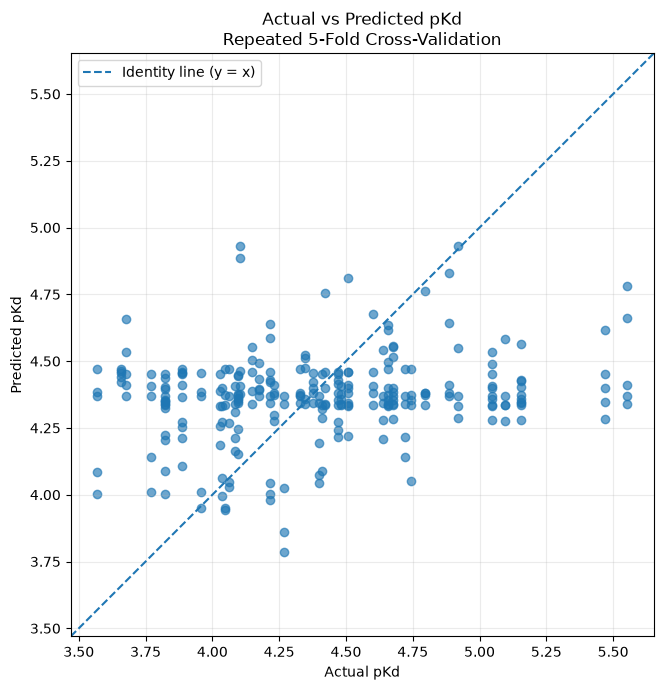

Number of predictions: 265
Scatter plot saved to: /data/Zira/Chemprop_Kd_Mann/3_53/evaluation/actual_vs_predicted_scatter.png


In [14]:

########################################
# Cell 14. Actual vs Predicted pKd Scatter Plot
########################################

import matplotlib.pyplot as plt
import numpy as np

# Prepare prediction data
plot_df = all_predictions_df[
    ["pKd_actual", "pKd_pred"]
].dropna().copy()

# Calculate axis limits
min_value = min(
    plot_df["pKd_actual"].min(),
    plot_df["pKd_pred"].min()
)

max_value = max(
    plot_df["pKd_actual"].max(),
    plot_df["pKd_pred"].max()
)

padding = (max_value - min_value) * 0.05

axis_min = min_value - padding
axis_max = max_value + padding

# Create scatter plot
plt.figure(figsize=(7, 7))

plt.scatter(
    plot_df["pKd_actual"],
    plot_df["pKd_pred"],
    alpha=0.65
)

# Add identity line
plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--",
    linewidth=1.5,
    label="Identity line (y = x)"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")

plt.title(
    "Actual vs Predicted pKd\n"
    "Repeated 5-Fold Cross-Validation"
)

plt.xlim(axis_min, axis_max)
plt.ylim(axis_min, axis_max)

plt.legend()
plt.grid(alpha=0.25)
plt.gca().set_aspect("equal", adjustable="box")

plt.tight_layout()

# Save figure
SCATTER_PATH = (
    FOLDERS["evaluation"] /
    "actual_vs_predicted_scatter.png"
)

plt.savefig(
    SCATTER_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Number of predictions:", len(plot_df))
print("Scatter plot saved to:", SCATTER_PATH)
